In [50]:
import pandas as pd
import numpy as np

In [52]:
clim= pd.read_csv('cleaned_dataset.csv') # using the cleaned data set

In [54]:
clim

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,year,month,day
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,2007,10,2
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,2008,1,5
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,2008,2,14
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,2008,2,15
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,2008,2,15
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3141,ID_2CDAAE58,Rural,Female,2022-05-06,92.0,21.869711,24.824496,19.501874,4.250624,0.572884,33.506221,"Kiboyo, Iganga, Uganda",0,2022,5,6
3142,ID_8099FB9C,Peri_urban,Male,2022-05-07,0.0,21.957913,25.210808,19.286763,4.133601,0.614154,33.483544,"Nakavule B, Iganga, Uganda",1,2022,5,7
3143,ID_8A614F8B,Rural,Female,2022-05-15,0.0,22.436613,26.813967,18.726832,1.473170,0.550000,33.450000,"Luyira, Mayuge, Uganda",0,2022,5,15
3144,ID_CB4F8F61,Peri_urban,Male,2022-05-18,0.0,22.445975,25.554302,19.487528,1.220220,0.728530,33.468347,"Bulumwaki Church of Uganda Primary School, Kal...",1,2022,5,18


In [56]:
clim.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3146 entries, 0 to 3145
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    3146 non-null   object 
 1   zone                  3146 non-null   object 
 2   gender                3146 non-null   object 
 3   deathdate             3146 non-null   object 
 4   age                   3146 non-null   float64
 5   avg_temperature       3146 non-null   float64
 6   max_temperature       3146 non-null   float64
 7   min_temperature       3146 non-null   float64
 8   precipitation         3146 non-null   float64
 9   latitude              3146 non-null   float64
 10  longitude             3146 non-null   float64
 11  location              3146 non-null   object 
 12  is_climate_sensitive  3146 non-null   int64  
 13  year                  3146 non-null   int64  
 14  month                 3146 non-null   int64  
 15  day                  

In [58]:
clim['deathdate']=pd.to_datetime(clim['deathdate'])
clim['deathdate'].dtype

dtype('<M8[ns]')

In [62]:
# EDA will answer these questions:

# Distribution of climate-sensitive death
# 1. What proportion of recorded deaths is classified as climate-sensitive?
# 2. How are climate-sensitive and non-climate-sensitive deaths distributed?
# 3. Is there a significant imbalance between the two target classes?

#. Demographic vulnerability
# How does the proportion of climate-sensitive deaths vary across different age groups?
# Are there differences in climate-sensitive death proportions between males and females?
# Which age groups demonstrate the highest proportions of climate-sensitive deaths?
# Does the relationship between age and climate sensitivity differ by gender?

#   Geographical vulnerability
# How are recorded deaths distributed across geographical locations?
# Which locations have the highest proportions of climate-sensitive deaths?
# Are there noticeable differences in climate-sensitive death proportions across locations?
# Are geographical patterns consistent when differences in sample sizes are considered?

# . Temporal vulnerability
# How does the proportion of climate-sensitive deaths vary across different years?
# Are there particular months with higher proportions of climate-sensitive deaths?
# Do seasonal variations exist in the recorded climate-sensitive death proportions?
# Are monthly patterns consistent across different years?

In [65]:
# identifying the distribution of the target feature(climate sensitive death)
clim['is_climate_sensitive'].value_counts() 
# climate that is sensitive is assigned 1 while not sensitive is assigned 0

is_climate_sensitive
1    2047
0    1099
Name: count, dtype: int64

In [68]:
clim['is_climate_sensitive'].value_counts(normalize = True)* 100
# approximately 65 out of 100 distributionare classified as climate sensitive 
# while the 35 are classified as not sensitive
# this show the dataset is moderately imbalanced though, not severely.
# a classifer may favour the majority class when making decisons hence, we will look at
# considering various option to get the best such as logistic regression, decision tree, random forest

is_climate_sensitive
1    65.066751
0    34.933249
Name: proportion, dtype: float64

In [72]:
# investigating vulnerability by gender
gender_vulnerability = (
    clim.groupby('gender')['is_climate_sensitive']
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print(gender_vulnerability)

gender
Female    67.16
Male      63.16
Name: is_climate_sensitive, dtype: float64


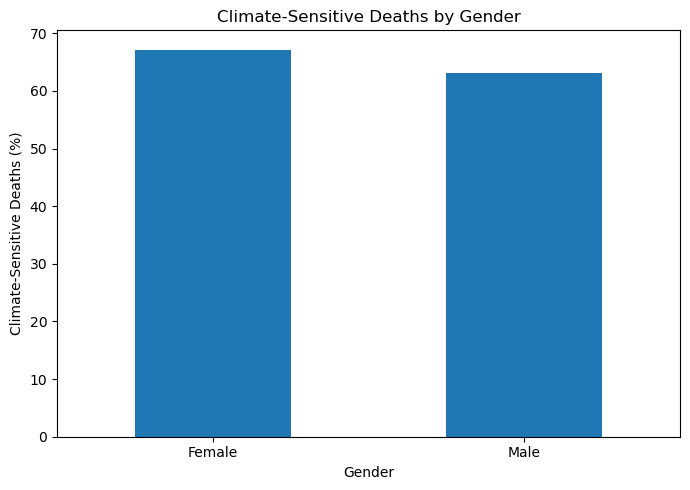

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
gender_vulnerability.plot(kind='bar', figsize=(7, 5))

plt.title('Climate-Sensitive Deaths by Gender')
plt.xlabel('Gender')
plt.ylabel('Climate-Sensitive Deaths (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [86]:
# grouping the ages into various groups 
# allows us to investigate whether certain age categories have greater climate vulnerability
bins = [0, 18, 30, 45, 60, 120]

labels = ['0-17', '18-29', '30-44', '45-59', '60+']

clim['age_group'] = pd.cut(
    clim['age'],
    bins=bins,
    labels=labels,
    right=False
)

In [89]:
# examining the new feature
clim['age_group'].value_counts().sort_index()

# age group 0-17 dominates the dataset whih accounts to 59.5% of the observations.
# the 60+ category is the second largest group and the 18-29 had the fewest observation.
# this tells us that age categories are not evenly distributed in the dataset

age_group
0-17     1872
18-29     183
30-44     237
45-59     208
60+       646
Name: count, dtype: int64

In [93]:
# investigating climate sensitivity by age group
age_vulnerability = clim.groupby(
    'age_group',
    observed=False
)['is_climate_sensitive'].mean() * 100
print(age_vulnerability)


age_group
0-17     82.051282
18-29    50.273224
30-44    53.164557
45-59    47.596154
60+      30.030960
Name: is_climate_sensitive, dtype: float64


In [113]:

# children(0-17) had the highest climate sensitivity rate
# young adults(18-29) approx 50.27% of the observations are climate sensitive
# adults (30-44) approx 53.16% slightly higher than the young adult category.
# middleaged adults(45-59) approx 47.60% showing a moderate reduction.
# older adults (60+) had the lowest rate at 30.03%.

# this shows that climate sensitivity decreases considerably across the age categories in the dataset.


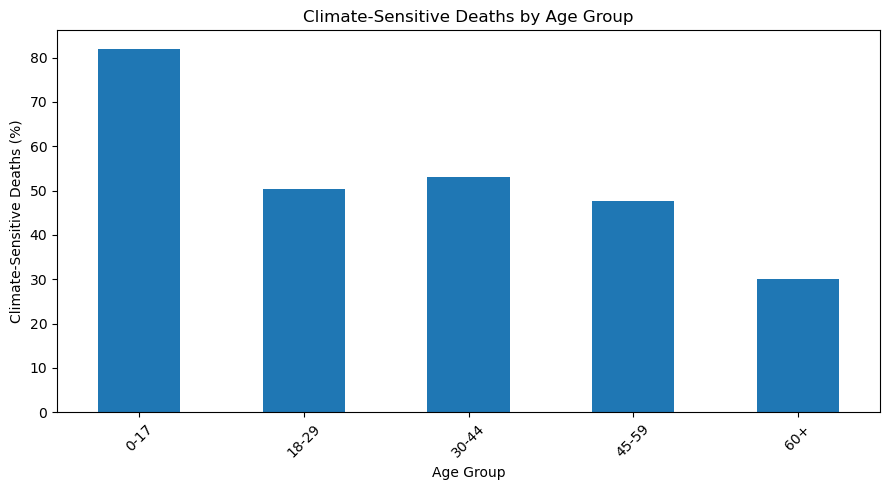

In [115]:
age_vulnerability.plot(kind='bar', figsize=(9, 5))

plt.title('Climate-Sensitive Deaths by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Climate-Sensitive Deaths (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [117]:
# investigating the age groups statistically
pd.crosstab(
    clim['age_group'],
    clim['is_climate_sensitive'],
    margins=True
)

is_climate_sensitive,0,1,All
age_group,,,
0-17,336,1536,1872
18-29,91,92,183
30-44,111,126,237
45-59,109,99,208
60+,452,194,646
All,1099,2047,3146


In [119]:
# Perforing chi square test to investigate if the relationship btw age group and climate
# sensitivity is statistically significant.
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    clim['age_group'],
    clim['is_climate_sensitive']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 646.7694909790036
P-value: 1.166406483768905e-138
Degrees of freedom: 4


In [121]:
# interpretation
# this shows that there is a strong statistical relationship btw age groups and climate sensitivity.
# in the dataset

In [123]:
# running Cramer's V to meaure the strength of their relationship
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print("Cramer's V:", cramers_v)
# there is a strong association

Cramer's V: 0.4534144989701499


In [125]:
# Age categorisation revealed substantial differences in climate sensitivity across 
# age groups. The 0–17 category recorded the highest sensitivity rate at 82.05%, 
# while the 60+ category recorded the lowest at 30.03%. 

# A Chi-square test confirmed a statistically significant association between age group 
# and climate sensitivity (χ² = 646.77, p = 1.17 × 10⁻¹³⁸). 

# Cramér's V of approximately 0.4534 indicated a strong association. 
# These findings suggest that age group may provide useful predictive information
# for our machine learning models.

In [130]:
# investigating whether proportion of climate sensitive deaths varies across locations and over time
location_analysis = (
    clim.groupby('location')['is_climate_sensitive']
    .agg(
        total_records='count',
        climate_sensitive='sum',
        vulnerability_rate='mean'
    )
)

location_analysis['vulnerability_rate'] = (
    location_analysis['vulnerability_rate'] * 100
).round(2)

location_analysis = location_analysis.sort_values(
    by='vulnerability_rate',
    ascending=False
)

print(location_analysis)

                                                    total_records  \
location                                                            
Buwaya, Entebbe City, Uganda                                   11   
Bukoyo, Iganga, Uganda                                         31   
Nawampendo, Bugweri, Uganda                                    34   
Bukwaya, Iganga, Uganda                                        79   
Nakavule A, Iganga, Uganda                                     43   
Buwaiswa, Mayuge, Uganda                                       48   
Nakigo Ii, Iganga, Uganda                                     116   
Kasokoso South, Iganga, Uganda                                114   
Nakigo I, Iganga, Uganda                                       49   
Nawanzu, Iganga, Uganda                                       146   
Walanga, Bugweri, Uganda                                       65   
Budhwege, Iganga, Uganda                                       80   
Luyira, Mayuge, Uganda            

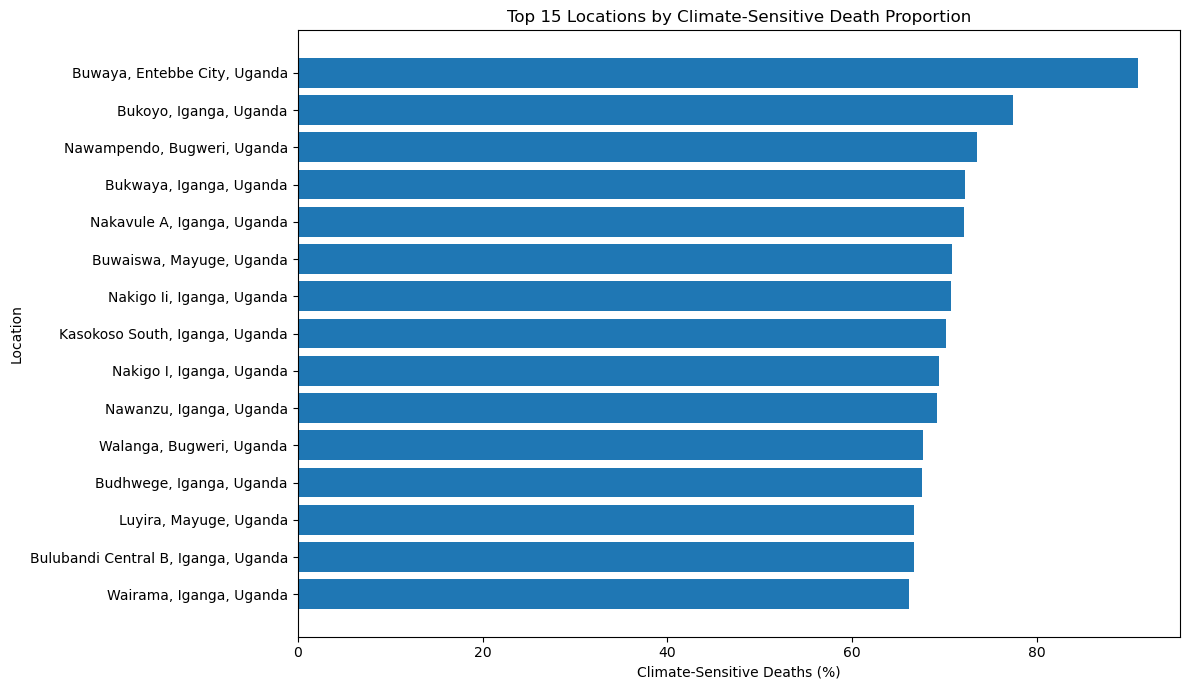

In [152]:
top_locations = location_analysis.head(15)

plt.figure(figsize=(12, 7))

plt.barh(
    top_locations.index,
    top_locations['vulnerability_rate']
)

plt.title('Top 15 Locations by Climate-Sensitive Death Proportion')
plt.xlabel('Climate-Sensitive Deaths (%)')
plt.ylabel('Location')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

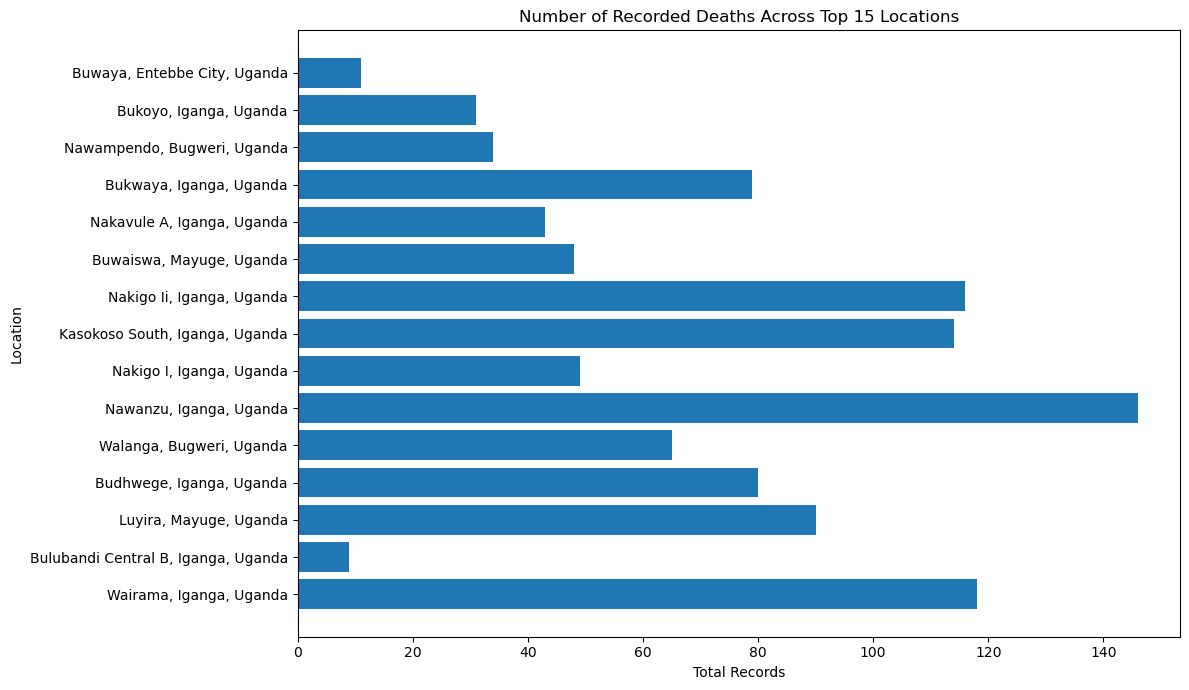

In [155]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_locations.index,
    top_locations['total_records']
)

plt.title('Number of Recorded Deaths Across Top 15 Locations')
plt.xlabel('Total Records')
plt.ylabel('Location')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [157]:
# Buwaya, Entebbe City, recorded the highest proportion at 90.91%, 
# followed by Bukoyo, Iganga (77.42%), Nawampendo, Bugweri (73.53%), Bukwaya, Iganga (72.15%) and Nakavule A, Iganga (72.09%).

#However, locations with relatively larger sample sizes also demonstrated elevated proportions.
# For instance, Nakigo II recorded 70.69% from 116 observations, Kasokoso South recorded 70.18% from 114 observations, while Nawanzu recorded 69.18% from 146 observations.
# The findings suggest geographical variation in climate-sensitive death classifications,
# with several locations recording proportions above the overall dataset average of approximately 65.07%.

# Nevertheless, differences in sample sizes must be considered when interpreting these results. 
# The observed patterns describe the distribution of climate-sensitive classifications among recorded deaths and do not independently establish differences in population-level mortality risk or geographical causation.

In [159]:
# to investigate the statistical significance 
from scipy.stats import chi2_contingency

location_target_table = pd.crosstab(
    clim['location'],
    clim['is_climate_sensitive']
)

chi2, p_value, dof, expected = chi2_contingency(
    location_target_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 25.886669029059536
P-value: 0.9323921192732986
Degrees of freedom: 38


In [161]:
print("Minimum expected frequency:", expected.min())

print(
    "Cells with expected frequency below 5:",
    (expected < 5).sum()
)

print(
    "Percentage below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

Minimum expected frequency: 0.6986649713922441
Cells with expected frequency below 5: 6
Percentage below 5: 7.69 %


In [163]:
# A Chi-square test of independence was conducted to examine the association between 
# geographical location and climate sensitivity. 
# The results showed no statistically significant association, χ²(38) = 25.89, p = 0.9324.
# Therefore, there is insufficient evidence to suggest that the distribution of 
# climate-sensitive deaths differs significantly across the recorded locations. 

# Although descriptive analysis revealed variations in sensitivity percentages, 
# these differences were not statistically significant.
# the descriptive analysis showed differences in climate sensitive death proportions across locations,
# but the available evidence from the statistical results did not establish a statistical
# significance

In [165]:

n = location_target_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        location_target_table.shape[0] - 1,
        location_target_table.shape[1] - 1
    ))
)

print("Cramer's V:", round(cramers_v, 4))

Cramer's V: 0.0907


In [167]:
# from this Cramer's V results, the association between location and climate sensitive death classification is very weak.
# overall conclusion is there is no statistically significant evidence of relation btw both features.


In [171]:
# Calcuating yearly vulnerabilty
year_analysis = (
    clim.groupby('year')['is_climate_sensitive']
    .agg(
        total_records='count',
        climate_sensitive='sum',
        vulnerability_rate='mean'
    )
)

year_analysis['vulnerability_rate'] = (
    year_analysis['vulnerability_rate'] * 100
).round(2)

print(year_analysis)

      total_records  climate_sensitive  vulnerability_rate
year                                                      
2007              1                  1              100.00
2008            113                 90               79.65
2009            444                342               77.03
2010            334                257               76.95
2011            319                210               65.83
2012            246                173               70.33
2013            270                152               56.30
2014            189                130               68.78
2015            192                118               61.46
2016            207                130               62.80
2017             75                 43               57.33
2018             83                 45               54.22
2019            157                 72               45.86
2020            184                 98               53.26
2021            270                145               53.

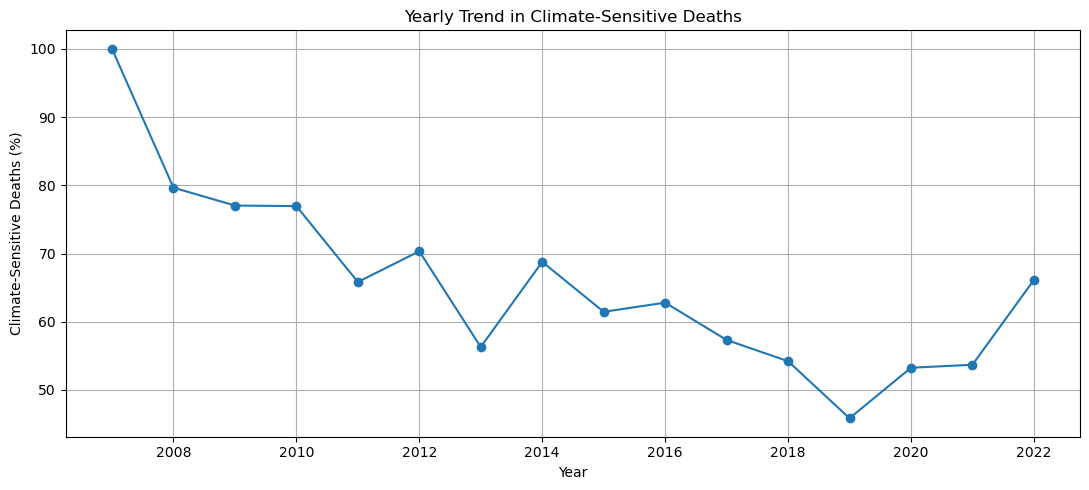

In [174]:
# visualising the yearly vulnerability trend
plt.figure(figsize=(11, 5))

plt.plot(
    year_analysis.index,
    year_analysis['vulnerability_rate'],
    marker='o'
)

plt.title('Yearly Trend in Climate-Sensitive Deaths')
plt.xlabel('Year')
plt.ylabel('Climate-Sensitive Deaths (%)')
plt.grid(True)
plt.tight_layout()
plt.show()

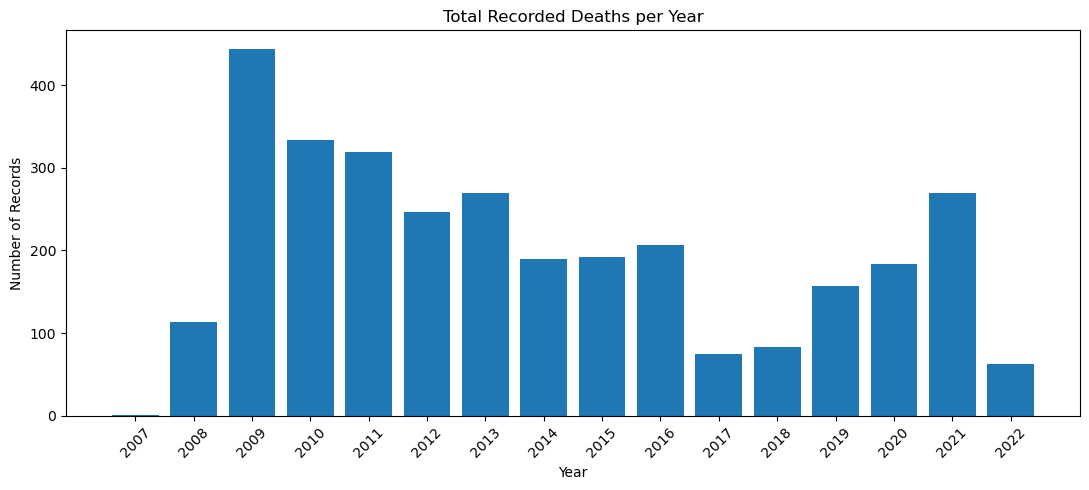

In [177]:
# visualising yearly record counts
plt.figure(figsize=(11, 5))

plt.bar(
    year_analysis.index.astype(str),
    year_analysis['total_records']
)

plt.title('Total Recorded Deaths per Year')
plt.xlabel('Year')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

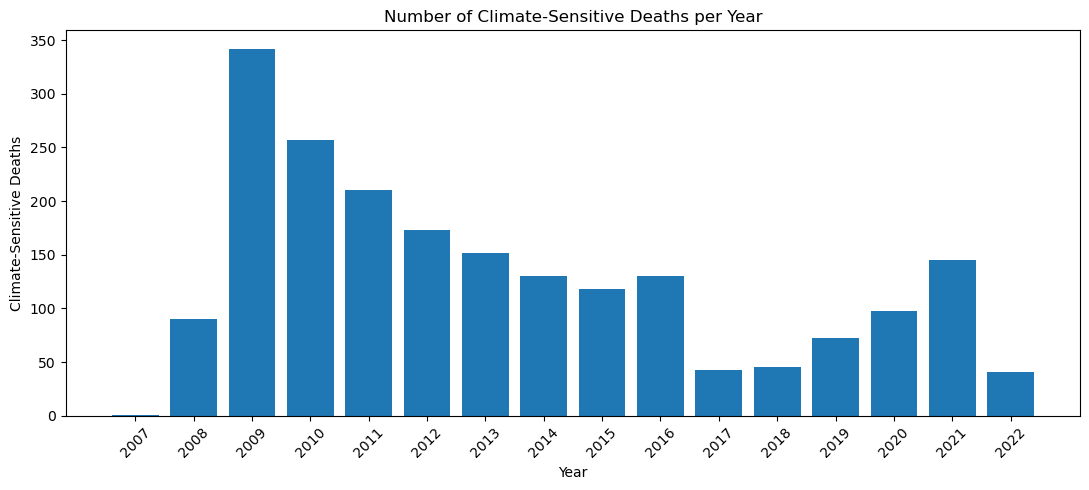

In [180]:
# examing the actual number of climate sensitive deaths
plt.figure(figsize=(11, 5))

plt.bar(
    year_analysis.index.astype(str),
    year_analysis['climate_sensitive']
)

plt.title('Number of Climate-Sensitive Deaths per Year')
plt.xlabel('Year')
plt.ylabel('Climate-Sensitive Deaths')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [183]:
from scipy.stats import chi2_contingency

year_target_table = pd.crosstab(
    clim['year'],
    clim['is_climate_sensitive']
)

chi2, p_value, dof, expected = chi2_contingency(
    year_target_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

print("Minimum expected frequency:", expected.min())

print(
    "Percentage of expected frequencies below 5:",
    (expected < 5).sum() / expected.size * 100
)

Chi-square statistic: 133.1140141941804
P-value: 5.2138829878038594e-21
Degrees of freedom: 15
Minimum expected frequency: 0.3493324856961221
Percentage of expected frequencies below 5: 6.25


In [190]:
# this shows that year and climate sensitive classification are statistically significant.
# but its association is relatively weak. 

In [192]:
import numpy as np

n = year_target_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        year_target_table.shape[0] - 1,
        year_target_table.shape[1] - 1
    ))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.20569916605292743


In [195]:
# MONTHLY VULNERABILITY
# identifying the total deaths per month, number of climate sensitive deaths and percentage
month_analysis = (
    clim.groupby('month')['is_climate_sensitive']
    .agg(
        total_records='count',
        climate_sensitive='sum',
        vulnerability_rate='mean'
    )
)

month_analysis['vulnerability_rate'] = (
    month_analysis['vulnerability_rate'] * 100
).round(2)

print(month_analysis)

       total_records  climate_sensitive  vulnerability_rate
month                                                      
1                261                181               69.35
2                249                162               65.06
3                233                139               59.66
4                252                171               67.86
5                305                202               66.23
6                314                205               65.29
7                275                183               66.55
8                262                168               64.12
9                227                139               61.23
10               205                125               60.98
11               281                194               69.04
12               282                178               63.12


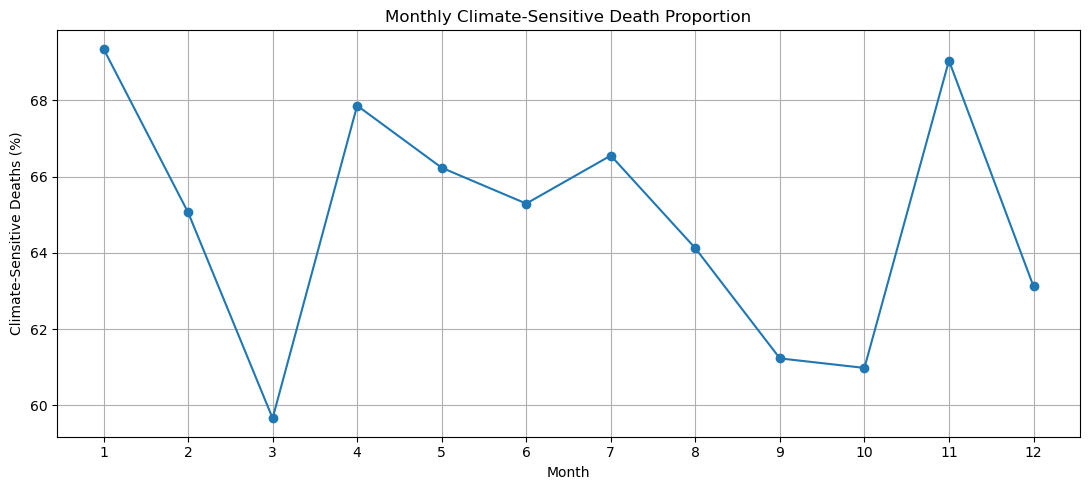

In [292]:
# visualize monthly vulnerability
plt.figure(figsize=(11, 5))

plt.plot(
    month_analysis.index,
    month_analysis['vulnerability_rate'],
    marker='o'
)

plt.title('Monthly Climate-Sensitive Death Proportion')
plt.xlabel('Month')
plt.ylabel('Climate-Sensitive Deaths (%)')
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

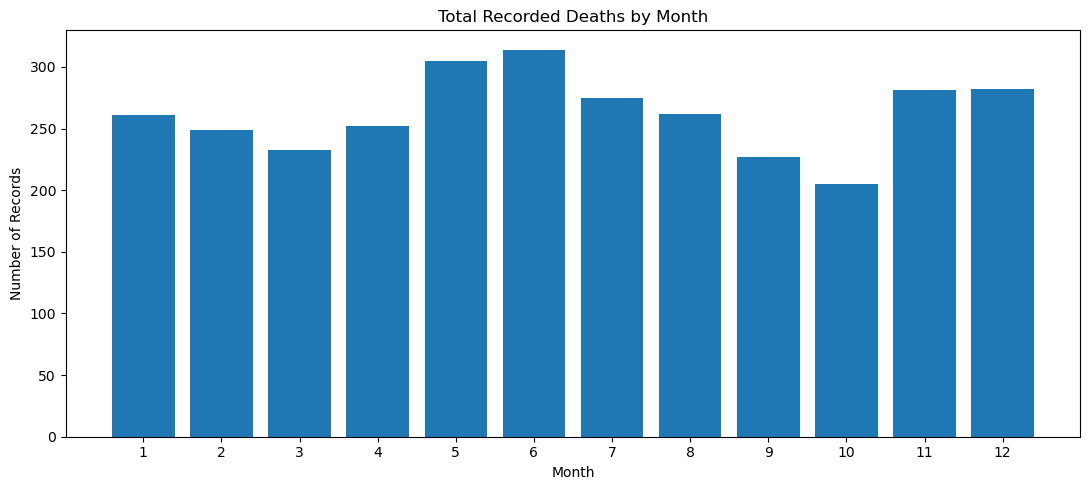

In [294]:
# visualising monthly record counts
plt.figure(figsize=(11, 5))

plt.bar(
    month_analysis.index,
    month_analysis['total_records']
)

plt.title('Total Recorded Deaths by Month')
plt.xlabel('Month')
plt.ylabel('Number of Records')
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

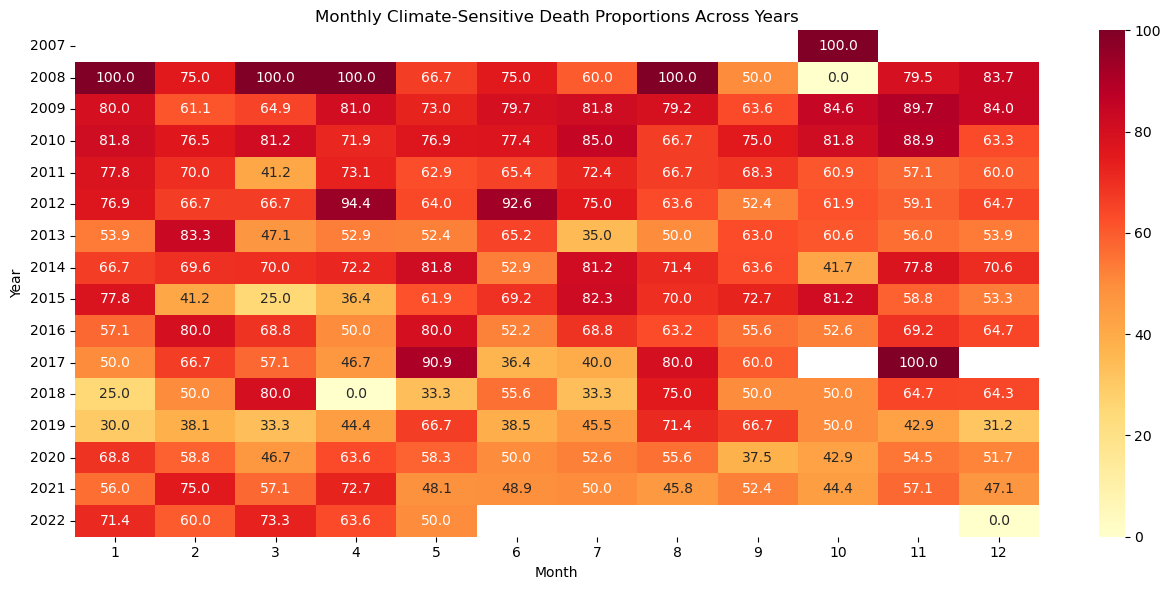

In [296]:
monthly_heatmap = monthly_year_analysis.pivot(
    index='year',
    columns='month',
    values='is_climate_sensitive'
)

plt.figure(figsize=(13, 6))

sns.heatmap(
    monthly_heatmap,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)

plt.title('Monthly Climate-Sensitive Death Proportions Across Years')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

In [297]:
# The monthly analysis revealed variations in climate-sensitive death classification across the year. 
# January recorded the highest proportion at 69.35%, followed by November at 69.04%, 
# while March recorded the lowest proportion at 59.66%.
# September and October also showed relatively lower proportions.
# Although some months exhibited higher proportions than others,
# the overall differences were moderate, suggesting that monthly variation alone may not explain the classification patterns. 
# Further statistical testing is required to determine whether the observed differences are statistically significant.

In [300]:
month_target_table = pd.crosstab(
    clim['month'],
    clim['is_climate_sensitive']
)

chi2, p_value, dof, expected = chi2_contingency(
    month_target_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())
print(
    "Percentage below 5:",
    (expected < 5).sum() / expected.size * 100
)

Chi-square statistic: 11.92209525634794
P-value: 0.36952750126951
Degrees of freedom: 11
Minimum expected frequency: 71.61315956770503
Percentage below 5: 0.0


In [302]:
# month and climate sensitive classification are independent.
#  there is no statistical significant between them

In [304]:
n = month_target_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            month_target_table.shape[0] - 1,
            month_target_table.shape[1] - 1
        )
    )
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.06155976235221151


In [306]:
# this concluded that there relation/ association is exteremly weak even though
# in the descriptive analysis, January and November recorded high proportions, the differences
# across the months are not statistically significant.

In [308]:
#. creating seasonal patterns 
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

clim['season'] = clim['month'].apply(get_season)

In [310]:
# SEASONAL DISTRIBUTION

clim['season'].value_counts()
# the total of observations in each seasons
# summer has the highest number of observations while Autumn has the lowest number.
# there is no extreme seasonal imbalance as the observations are evenly distributed across.

season
Summer    851
Winter    792
Spring    790
Autumn    713
Name: count, dtype: int64

In [312]:
# examining climate senstivity across seasons
# percentage of climate sensitive observations in each season
clim.groupby('season')['is_climate_sensitive'].mean() * 100

season
Autumn    64.235624
Spring    64.810127
Summer    65.334900
Winter    65.782828
Name: is_climate_sensitive, dtype: float64

In [314]:
# Winter records the highest climate sensitivity rate(65.78%), Summer follows closely 
# Autumn records the lowest rate.
# this shows that season alone may not be a strong distinguishing factor for predicitng 
# climate sensitivity.

In [316]:
#  Precipitation
# because precipitation is positively skewed, a logarithmic transformation can help to 
# reduce the influence of extremely large values.(cal the log of one plus the original value
# allowing zero precipitation )
clim['precipitation_log'] = np.log1p(clim['precipitation'])

In [318]:
clim

,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,year,month,day,age_group,season,precipitation_log
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,33.546344,"Izimba, Iganga, Uganda",1,2007,10,2,30-44,Autumn,0.668650
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,2008,1,5,0-17,Winter,0.051978
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,33.483655,"Buluza, Iganga, Uganda",1,2008,2,14,30-44,Winter,0.086498
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,33.490326,"Nawanzu, Iganga, Uganda",1,2008,2,15,0-17,Winter,0.252170
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,34.226647,"Magada, Mbale City, Bugisa sub-region, Eastern...",0,2008,2,15,60+,Winter,0.252170
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3141,ID_2CDAAE58,Rural,Female,2022-05-06,92.0,21.869711,24.824496,19.501874,4.250624,0.572884,33.506221,"Kiboyo, Iganga, Uganda",0,2022,5,6,60+,Spring,1.658347
3142,ID_8099FB9C,Peri_urban,Male,2022-05-07,0.0,21.957913,25.210808,19.286763,4.133601,0.614154,33.483544,"Nakavule B, Iganga, Uganda",1,2022,5,7,0-17,Spring,1.635807
3143,ID_8A614F8B,Rural,Female,2022-05-15,0.0,22.436613,26.813967,18.726832,1.473170,0.550000,33.450000,"Luyira, Mayuge, Uganda",0,2022,5,15,0-17,Spring,0.905501
3144,ID_CB4F8F61,Peri_urban,Male,2022-05-18,0.0,22.445975,25.554302,19.487528,1.220220,0.728530,33.468347,"Bulumwaki Church of Uganda Primary School, Kal...",1,2022,5,18,0-17,Spring,0.797606


In [320]:
# calculating  the original and the transformed precipitation distribution.
print("Original skewness:",
      clim['precipitation'].skew())

print("Transformed skewness:",
      clim['precipitation_log'].skew())

Original skewness: 1.9813247104233696
Transformed skewness: 0.4436350410607258


In [322]:
# this showed that the log transformation has reduced the skweness from 1.98 to 0.44
# the distribution is more symmetrical and the influence of extremely large precipitation
# values has been compressed.

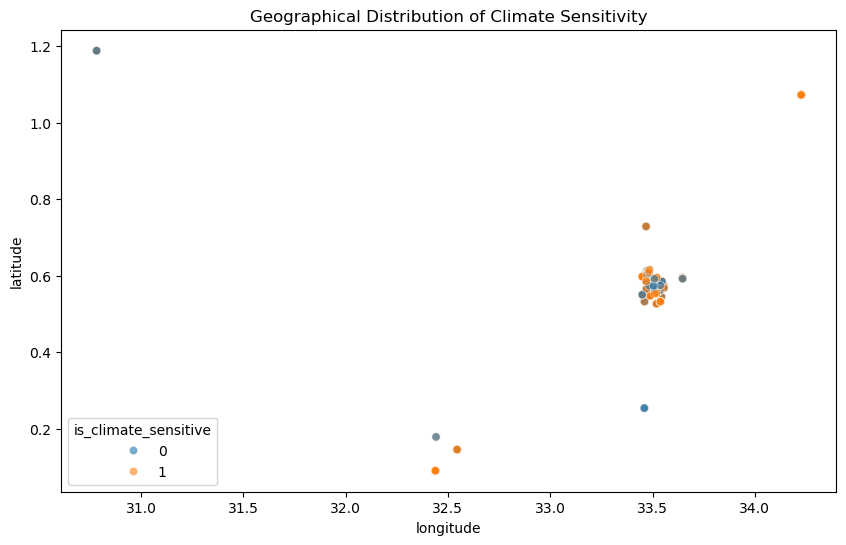

In [324]:
# exploring latitude and longitude because cordinates can help us investigate geographical
# patterns in climate vulnerability
plt.figure(figsize=(10, 6)) # visualising relationship btw latitude and longitude

sns.scatterplot(
    data=clim,
    x='longitude',
    y='latitude',
    hue='is_climate_sensitive',
    alpha=0.6
)

plt.title('Geographical Distribution of Climate Sensitivity')
plt.show()

In [326]:
# Most sampled locations are geographically concentrated in one area.
# Climate-sensitive and non-climate-sensitive observations overlap geographically.
# Some observations are spatially distant from the main cluster.
# Longitude and latitude alone do not establish why certain locations are climate-sensitive.

In [328]:
clim.groupby('is_climate_sensitive')[
    ['latitude', 'longitude']
].mean()  # this calculates the mean cordinates for each target category

,latitude,longitude
is_climate_sensitive,,
0,0.633237,33.411415
1,0.628634,33.405308


In [330]:
# to test for statistical significance 
from scipy.stats import mannwhitneyu

for feature in ['latitude', 'longitude']:

    group0 = clim.loc[
        clim['is_climate_sensitive'] == 0, feature
    ]

    group1 = clim.loc[
        clim['is_climate_sensitive'] == 1, feature
    ]

    stat, p = mannwhitneyu(
        group0, group1, alternative='two-sided'
    )

    print(f'{feature}:')
    print('U-statistic:', stat)
    print('P-value:', p)
    print()

latitude:
U-statistic: 1154822.0
P-value: 0.21614051192786143

longitude:
U-statistic: 1127698.0
P-value: 0.9057611371298789



In [332]:
# The Mann–Whitney U test was conducted to investigate whether geographical coordinates
# differed between climate-sensitive and non-climate-sensitive observations. 
# The results showed no statistically significant difference in latitude (p = 0.2161) 
# or longitude (p = 0.9058) between the two groups at the 5% significance level. 
# This suggests that the geographical coordinates, when examined individually,
# do not demonstrate a significant distributional distinction between the target classes.

In [334]:
clim['deathdate'].agg(['min', 'max'])

min   2007-10-02
max   2022-12-13
Name: deathdate, dtype: datetime64[ns]

In [336]:
# checking the categories distributions
for col in ['zone', 'gender', 'location']:
    print(f'\n{col.upper()}')
    print(clim[col].value_counts())


ZONE
zone
Rural         1972
Peri_urban    1174
Name: count, dtype: int64

GENDER
gender
Male      1645
Female    1501
Name: count, dtype: int64

LOCATION
location
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Eastern Region, Uganda       211
Brac Uganda Iganga Regional Branch, Bikadho Road, Nkaatu Propeer, Kasokoso North, Iganga, Uganda                       207
Magada, Mbale City, Bugisa sub-region, Eastern Region, Uganda                                                          158
Bulumwaki Church of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Eastern Region, Uganda    155
Nawanzu, Iganga, Uganda                                                                                                146
Kabila, Kasonga, Kikuube, Western Region, Uganda                                                                       128
Nawansinge, Iganga, Uganda                                                                       